[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Lea-2005/tpi-analisis-de-datos-grupo-3/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb)

# TPI — Introducción al Análisis de Datos
## Análisis de la cancelación de clientes (Churn) en una empresa de telecomunicaciones

**División:** 143 · **Docente:** Zotti, Enzo Martín · **Fecha:** octubre 2026

**Integrantes:**
- Mamani, Leandro
- Leyes, Agustín
- Guantay, Marcos
- Verdecanna, Luciano

> **Dataset:** *Telco Customer Churn* (Kaggle / IBM Sample Data Sets).
> Este notebook está pensado para ejecutarse de principio a fin en Google Colab: *Entorno de ejecución → Ejecutar todas*.

---
# Parte A —  A.1 Fundamentos, Ingesta y Limpieza de Datos

## A.0 Configuración del entorno
Importamos las librerías y fijamos opciones de visualización para que las salidas sean legibles y reproducibles.

In [144]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Semilla fija: cualquier operación aleatoria (muestreos, jitter de gráficos) da siempre el mismo resultado
SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 2.2.3 | numpy 2.4.6 | seaborn 0.13.2


##  A.1.1 Definición del problema de negocio

Una empresa de telecomunicaciones pierde clientes que cancelan su suscripción
(churn). Esto es un problema porque cada baja significa un ingreso perdido, y
captar un cliente nuevo cuesta más que retener uno existente. El objetivo de este trabajo es identificar qué características distinguen a los clientes que cancelan, para que la empresa pueda orientar acciones de retención.

### A.1.2 Variable objetivo


La variable de interés principal es `Churn`, una variable cualitativa binaria: `Yes`
si el cliente canceló el servicio y `No` si continúa. Se utilizará para analizar la
cancelación del servicio en relación con las características de los clientes
(tipo de contrato, antigüedad, cargos mensuales, método de pago, entre otras).

### A.1.3 Hipótesis analíticas

- **H1:** Los clientes con contrato mes a mes cancelan más que los de contrato
  anual o bianual, porque no tienen un compromiso que los retenga.
- **H2:** Los clientes con menor antigüedad (`tenure`) cancelan más, porque aún no
  están fidelizados con el servicio.
- **H3:** Los clientes con cargos mensuales más altos (`MonthlyCharges`) cancelan
  más, porque son más sensibles al precio y buscan alternativas.

Estas hipótesis se verificarán en el análisis exploratorio.


## A.2 Ingesta de datos
Cargamos el CSV desde el repositorio público de IBM (misma fuente que el dataset de Kaggle), lo que permite ejecutar el notebook en Colab sin credenciales. Si existe una copia local en `data/raw/`, se usa esa.

In [145]:
RUTA_LOCAL = "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
URL_DATOS = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
             "master/data/Telco-Customer-Churn.csv")

fuente = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else URL_DATOS
df_raw = pd.read_csv(fuente)

print(f"Fuente: {fuente}")
print(f"Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Fuente: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Dimensiones: 7,043 filas x 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [146]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Cada **fila representa un cliente** y cada **columna un atributo** de ese cliente. El dataset tiene 7.043 clientes y 21 variables. A simple vista, `info()` no muestra valores nulos, pero `TotalCharges` aparece como texto (`object`) cuando debería ser numérica: es una primera señal de un problema de calidad que se trata en A.4.

## A.3 Clasificación del dataset y de las variables

### A.3.1 Tipo de datos según su estructura

El dataset Telco Customer Churn es de tipo estructurado: está organizado en una tabla donde cada fila representa a un cliente y cada columna una característica (antigüedad, tipo de contrato, cargos, etc.). Todas las columnas tienen un nombre y un tipo de dato definido, y se almacena en un archivo CSV, que se puede cargar directamente en un DataFrame de Pandas sin transformaciones previas.

No es **semi-estructurado** (como JSON o XML, donde cada registro puede tener campos distintos o anidados) ni **no estructurado** (texto libre, imágenes, audio), ya que no requiere ningún proceso previo para extraer los campos.

### A.3.2 Relevamiento de variables
Clasificamos cada variable según la teoría estadística y la contrastamos con el `dtype` que Pandas le asigna por defecto al leer el CSV.

In [147]:
clasificacion_teorica = {
    "customerID":       ("Cualitativa", "Nominal (identificador)", "Código único del cliente"),
    "gender":           ("Cualitativa", "Nominal dicotómica",      "Género del cliente"),
    "SeniorCitizen":    ("Cualitativa", "Nominal dicotómica",      "Adulto mayor (1) o no (0)"),
    "Partner":          ("Cualitativa", "Nominal dicotómica",      "Tiene pareja"),
    "Dependents":       ("Cualitativa", "Nominal dicotómica",      "Tiene personas a cargo"),
    "tenure":           ("Cuantitativa", "Discreta",               "Antigüedad en meses"),
    "PhoneService":     ("Cualitativa", "Nominal dicotómica",      "Tiene telefonía"),
    "MultipleLines":    ("Cualitativa", "Nominal",                 "Tiene múltiples líneas"),
    "InternetService":  ("Cualitativa", "Nominal",                 "Tipo de conexión a internet"),
    "OnlineSecurity":   ("Cualitativa", "Nominal",                 "Servicio de seguridad online"),
    "OnlineBackup":     ("Cualitativa", "Nominal",                 "Servicio de backup online"),
    "DeviceProtection": ("Cualitativa", "Nominal",                 "Protección de dispositivos"),
    "TechSupport":      ("Cualitativa", "Nominal",                 "Soporte técnico"),
    "StreamingTV":      ("Cualitativa", "Nominal",                 "Streaming de TV"),
    "StreamingMovies":  ("Cualitativa", "Nominal",                 "Streaming de películas"),
    "Contract":         ("Cualitativa", "Ordinal",                 "Duración del contrato"),
    "PaperlessBilling": ("Cualitativa", "Nominal dicotómica",      "Factura electrónica"),
    "PaymentMethod":    ("Cualitativa", "Nominal",                 "Medio de pago"),
    "MonthlyCharges":   ("Cuantitativa", "Continua",               "Cargo mensual (USD)"),
    "TotalCharges":     ("Cuantitativa", "Continua",               "Cargo total acumulado (USD)"),
    "Churn":            ("Cualitativa", "Nominal dicotómica",      "Canceló el servicio (variable objetivo)"),
}

tabla_variables = pd.DataFrame.from_dict(
    clasificacion_teorica, orient="index",
    columns=["tipo_teorico", "subtipo", "descripcion"])
tabla_variables["dtype_pandas"] = df_raw.dtypes.astype(str)
tabla_variables["valores_unicos"] = df_raw.nunique()

# Hay coherencia cuando una variable cuantitativa tiene dtype numérico
# y una cualitativa tiene dtype de texto.
es_numerico = df_raw.dtypes.apply(pd.api.types.is_numeric_dtype)
tabla_variables["coherente"] = np.where(
    (tabla_variables["tipo_teorico"] == "Cuantitativa") == es_numerico, "Sí", "NO")

tabla_variables

,tipo_teorico,subtipo,descripcion,dtype_pandas,valores_unicos,coherente
customerID,Cualitativa,Nominal (identificador),Código único del cliente,object,7043,Sí
gender,Cualitativa,Nominal dicotómica,Género del cliente,object,2,Sí
SeniorCitizen,Cualitativa,Nominal dicotómica,Adulto mayor (1) o no (0),int64,2,NO
Partner,Cualitativa,Nominal dicotómica,Tiene pareja,object,2,Sí
Dependents,Cualitativa,Nominal dicotómica,Tiene personas a cargo,object,2,Sí
tenure,Cuantitativa,Discreta,Antigüedad en meses,int64,73,Sí
PhoneService,Cualitativa,Nominal dicotómica,Tiene telefonía,object,2,Sí
MultipleLines,Cualitativa,Nominal,Tiene múltiples líneas,object,3,Sí
InternetService,Cualitativa,Nominal,Tipo de conexión a internet,object,3,Sí
OnlineSecurity,Cualitativa,Nominal,Servicio de seguridad online,object,3,Sí


In [148]:
print("Variables cuya clasificación teórica no coincide con el dtype de Pandas:")
tabla_variables.loc[tabla_variables["coherente"] == "NO",
                    ["tipo_teorico", "subtipo", "dtype_pandas"]]

Variables cuya clasificación teórica no coincide con el dtype de Pandas:


,tipo_teorico,subtipo,dtype_pandas
SeniorCitizen,Cualitativa,Nominal dicotómica,int64
TotalCharges,Cuantitativa,Continua,object


**Resumen del relevamiento:** 3 variables cuantitativas (1 discreta y 2 continuas) y 18 cualitativas (17 nominales, entre ellas el identificador, y 1 ordinal).

**Contraste teoría vs. Pandas.** Pandas infiere el tipo a partir del contenido del archivo y no del significado de la variable. Eso produce dos discrepancias:

1. **`SeniorCitizen` → `int64`**: está codificada como 0/1, por eso Pandas la lee como número entero. Conceptualmente es una **categórica nominal dicotómica**: calcular su media o su desvío no tiene sentido de negocio (aunque la media coincide con la proporción de adultos mayores). Se convierte a categoría.
2. **`TotalCharges` → `object` (texto)**: es una variable **cuantitativa continua**, pero contiene cadenas vacías (`" "`) que impiden la conversión automática a número. Se corrige en A.4.

Otras observaciones:
- **`tenure`** se mide en meses enteros, por lo que es **discreta**, aunque se puede tratar como continua en los gráficos dado su rango (0 a 72).
- **`MonthlyCharges`** y **`TotalCharges`** son importes monetarios. En sentido estricto se miden en centavos, pero se tratan como **continuas** por convención.
- **`Contract`** es **ordinal** porque sus categorías tienen un orden natural de compromiso: *Month-to-month < One year < Two year*. Se le asignará un tipo categórico ordenado.
- Las demás variables cualitativas quedan como `object` (texto). Convertirlas a `category` reduce el uso de memoria y explicita su naturaleza.

## A.4 Manipulación de datos
 Trabajamos sobre una copia (df) para conservar intacto el dataset original (df_raw) como referencia.
### A.4.1 Carga y selección

El dataset ya fue cargado en un DataFrame de Pandas. A continuación se aplican
filtros con múltiples condiciones lógicas, combinadas con los operadores `&` (y) y
`|` (o), para aislar segmentos de clientes relevantes para el análisis de la
cancelación.

In [149]:
df = df_raw.copy()


**Filtro 1: clientes nuevos con facturas altas.** Se seleccionan los clientes con
menos de 12 meses de antigüedad y cargos mensuales superiores a 70, un perfil que
podría tener mayor propensión a cancelar por no estar aún fidelizado.

In [150]:

nuevos_caros = df[(df["tenure"] < 12) & (df["MonthlyCharges"] > 70)]
nuevos_caros

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
31,4929-XIHVW,Male,1,Yes,No,2,Yes,No,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),95.50,181.65,No
39,8168-UQWWF,Female,0,No,No,11,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),97.85,1105.4,Yes
47,7760-OYPDY,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,80.65,144.15,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7008,1980-KXVPM,Female,1,No,No,3,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Credit card (automatic),75.05,256.25,Yes
7010,0723-DRCLG,Female,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,74.45,74.45,Yes
7018,1122-JWTJW,Male,0,Yes,Yes,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.65,70.65,Yes
7032,6894-LFHLY,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,75.75,75.75,Yes


In [151]:
len(nuevos_caros)

826

El filtro devuelve 826 clientes, cerca del 11,7% del total. Se trata de clientes
recientes que ya pagan facturas elevadas, un segmento relevante para analizar
porque podría estar más expuesto a la cancelación.

In [152]:
nuevos_caros["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
Yes,68.64
No,31.36


In [153]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.46
Yes,26.54


En este segmento la tasa de cancelación es de 68,6%, frente a 26,5% en el total de
clientes. Esto indica que los clientes recientes con facturas altas cancelan mucho
más que el cliente promedio, por lo que son un segmento de riesgo.

**Filtro 2: clientes con contrato anual o bianual.** Se seleccionan los clientes
con contrato de un año o de dos años, es decir, aquellos que tienen un compromiso
de permanencia. Este segmento sirve como referencia para comparar contra los
clientes mes a mes.

In [154]:
contrato_largo = df[(df["Contract"] == "One year") | (df["Contract"] == "Two year")]
contrato_largo

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No
11,7469-LKBCI,Male,0,No,No,16,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),18.95,326.8,No
12,8091-TTVAX,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),100.35,5681.1,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7036,7750-EYXWZ,Female,0,No,No,12,No,No phone service,DSL,No,Yes,Yes,Yes,Yes,Yes,One year,No,Electronic check,60.65,743.3,No
7037,2569-WGERO,Female,0,No,No,72,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No


In [155]:
len(contrato_largo)

3168

El filtro devuelve 3.168 clientes, alrededor del 45% del total. Esto significa
que algo menos de la mitad de la base tiene un compromiso de permanencia, y que el
55% restante (clientes mes a mes) puede irse sin penalidad. Para la empresa, ese
segmento es donde se concentra el riesgo de fuga.

 **Filtro 3: clientes mes a mes que cancelaron.**
Se seleccionan los clientes con
contrato mensual que abandonaron el servicio. Este segmento permite dimensionar
cuánto del churn se concentra en los clientes sin compromiso de permanencia.

In [156]:
se_fueron_mensual = df[(df["Contract"] == "Month-to-month") & (df["Churn"] == "Yes")]
se_fueron_mensual

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
13,0280-XJGEX,Male,0,No,No,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7018,1122-JWTJW,Male,0,Yes,Yes,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.65,70.65,Yes
7026,8775-CEBBJ,Female,0,No,No,9,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),44.20,403.35,Yes
7032,6894-LFHLY,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,75.75,75.75,Yes
7034,0639-TSIQW,Female,0,No,No,67,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,Yes,No,Month-to-month,Yes,Credit card (automatic),102.95,6886.25,Yes


In [157]:
len(se_fueron_mensual)

1655

In [158]:
total_churn = len(df[df["Churn"] == "Yes"])
print("Total de clientes que cancelaron:", total_churn)

print("Clientes mensuales que cancelaron:", len(se_fueron_mensual))
len(se_fueron_mensual) / total_churn * 100

Total de clientes que cancelaron: 1869
Clientes mensuales que cancelaron: 1655


88.55002675227395

El filtro devuelve 1.655 clientes, cerca del 23,5% del total. Además, representan
aproximadamente el 88,55% de todos los clientes que cancelaron. Esto indica que la
fuga se concentra en los clientes sin compromiso de permanencia, por lo que la
empresa podría evaluar acciones de retención sobre ese segmento, por ejemplo
incentivos para migrar a contratos anuales.

### A.4.2 Agregación

Se utiliza `groupby` combinando agregaciones (conteo, promedio y suma) para resumir y segmentar la base de clientes según el método de pago y el tipo de servicio de internet. Esto permite ver cuántos clientes hay en cada segmento, cuánto pagan en promedio y cuánto aporta cada uno a la facturación mensual.

**Cantidad de clientes por método de pago.** Se agrupa por `PaymentMethod` y se
cuenta cuántos clientes utilizan cada uno, para conocer el peso de cada método
dentro de la base.

In [159]:
df.groupby("PaymentMethod").size()

,0
PaymentMethod,
Bank transfer (automatic),1544
Credit card (automatic),1522
Electronic check,2365
Mailed check,1612


El método más utilizado es el cheque electrónico, con 2.365 clientes (33,6% del
total), y el menos utilizado es la tarjeta de crédito automática, con 1.522 clientes
(21,6%). Los otros tres métodos están repartidos de forma bastante pareja, entre
21,6% y 22,9% de la base. El cheque electrónico concentra a uno de cada tres
clientes, por lo que resulta un segmento clave para analizar más adelante.

**Cargo mensual promedio por método de pago.** Se calcula el promedio de
`MonthlyCharges` dentro de cada método de pago, para ver si algún grupo de clientes
paga más que otro.

In [160]:
df.groupby("PaymentMethod")["MonthlyCharges"].mean().round(2)

,MonthlyCharges
PaymentMethod,
Bank transfer (automatic),67.19
Credit card (automatic),66.51
Electronic check,76.26
Mailed check,43.92


Los clientes que pagan con cheque electrónico tienen el cargo mensual promedio más
alto (76,26), mientras que los de cheque por correo tienen el más bajo (43,92), una
diferencia de unos 32 por mes. Transferencia y tarjeta automáticas quedan en un
punto intermedio y muy parecido entre sí (67,19 y 66,51). Esto indica que el método
de pago está asociado a planes de distinto costo, aunque no alcanza para afirmar
que uno cause al otro.

**Resumen por tipo de servicio de internet.** Se combinan tres agregaciones
(conteo, promedio y suma) para segmentar la base según `InternetService`: cuántos
clientes hay en cada segmento, cuánto paga cada uno en promedio y cuánto factura el
segmento en total por mes.

In [161]:
resumen = df.groupby("InternetService").agg(
    clientes=("customerID", "count"),
    cargo_promedio=("MonthlyCharges", "mean"),
    facturacion_total=("MonthlyCharges", "sum"),
)
resumen

,clientes,cargo_promedio,facturacion_total
InternetService,,,
DSL,2421,58.10,"140,665.35"
Fiber optic,3096,91.50,"283,284.40"
No,1526,21.08,"32,166.85"


In [162]:
resumen["pct_facturacion"] = (resumen["facturacion_total"] / resumen["facturacion_total"].sum() * 100).round(2)
resumen

,clientes,cargo_promedio,facturacion_total,pct_facturacion
InternetService,,,,
DSL,2421,58.10,"140,665.35",30.84
Fiber optic,3096,91.50,"283,284.40",62.11
No,1526,21.08,"32,166.85",7.05


El segmento con más clientes es fibra óptica, con 3.096 clientes (alrededor del 44%
de la base), seguido de DSL con 2.421 y de los clientes sin servicio de internet
con 1.526. La fibra óptica también tiene el cargo mensual promedio más alto (91,50),
frente a 58,10 de DSL y 21,08 de quienes no tienen internet. Como resultado, la
fibra óptica aporta el 62,11% de la facturación mensual total, aunque representa
menos de la mitad de los clientes, mientras que los clientes sin internet aportan
solo el 7,05%. Para la empresa, esto indica que el ingreso se concentra en los
clientes de fibra óptica, por lo que perder a uno de ellos tiene un costo mayor
que perder a uno de los otros segmentos.

### A.4.3 Transformación básica

**Renombrado de columnas.** Se renombran algunas columnas con nombres en español y
más descriptivos, para facilitar la lectura del análisis. Se mantienen sin cambios
las variables centrales del estudio (`tenure`, `MonthlyCharges`, `TotalCharges`,
`Contract`, `PaymentMethod` y `Churn`) para conservar la referencia con el
dataset original.

In [163]:
df = df.rename(columns={
     "customerID": "customer_id", "gender": "gender", "SeniorCitizen": "senior_citizen",
    "Partner": "partner", "Dependents": "dependents", "tenure": "tenure",
    "PhoneService": "phone_service", "MultipleLines": "multiple_lines",
    "InternetService": "internet_service", "OnlineSecurity": "online_security",
    "OnlineBackup": "online_backup", "DeviceProtection": "device_protection",
    "TechSupport": "tech_support", "StreamingTV": "streaming_tv",
    "StreamingMovies": "streaming_movies", "Contract": "contract",
    "PaperlessBilling": "paperless_billing", "PaymentMethod": "payment_method",
    "MonthlyCharges": "monthly_charges", "TotalCharges": "total_charges",
    "Churn": "churn", "Churn_flag": "churn_flag",
})
df.columns

Index(['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure', 'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract',
       'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'churn'],
      dtype='object')

In [164]:
# Crear variable numérica para el análisis de Churn
df["churn_flag"] = df["churn"].map({
    "No": 0,
    "Yes": 1
}).astype("int8")

### Renombramiento de columnas

Se realizó el renombramiento de las columnas del dataset mediante el método `rename()` de Pandas, con el objetivo de establecer una nomenclatura uniforme y facilitar la lectura y manipulación de los datos.

Se adoptó la convención `snake_case`, utilizando nombres en minúsculas y separando las palabras mediante guiones bajos (`_`) cuando corresponde.

Por ejemplo:
- `customerID` → `customer_id`
- `SeniorCitizen` → `senior_citizen`
- `MonthlyCharges` → `monthly_charges`
- `TotalCharges` → `total_charges`
- `PaperlessBilling` → `paperless_billing`

También se conservaron aquellas columnas que ya cumplían con la nomenclatura establecida, como `tenure`.

De esta manera, se consiguió una estructura de nombres consistente, facilitando el trabajo posterior de exploración, limpieza y análisis del dataset.

Creación de variable numérica churn_flag.

Se creó una nueva variable denominada churn_flag a partir de la columna original churn, mediante el método map() de Pandas.

Esta transformación permite representar la cancelación del servicio mediante valores numéricos binarios:

No → 0 (el cliente no canceló el servicio).

Yes → 1 (el cliente canceló el servicio).

Se conserva la variable original churn para los análisis categóricos y se utiliza churn_flag para facilitar los cálculos estadísticos, como la tasa global de cancelación y las tasas de churn por segmento de clientes.

**Eliminación de atributos irrelevantes.** Se elimina `customerID`, un código
único por cliente que sirve solo para identificarlo y no aporta información para
explicar la cancelación.

In [165]:
df = df.drop(columns=["customer_id"])
df.shape

(7043, 21)

Tras eliminar `customerID`, el dataset conserva las 7.043 filas y pasa de 22 a 21
columnas. Al ser un identificador único, no tiene valor analítico para explicar la
cancelación.


**Creación de columnas calculadas.** Se crea `gasto_estimado_total`, que estima
cuánto pagó cada cliente desde que contrató el servicio, multiplicando su cargo
mensual por su antigüedad en meses.

In [166]:
df["gasto_estimado_total"] = df["monthly_charges"] * df["tenure"]
df[["monthly_charges", "tenure", "gasto_estimado_total"]].head()

,monthly_charges,tenure,gasto_estimado_total
0,29.85,1,29.85
1,56.95,34,"1,936.30"
2,53.85,2,107.70
3,42.30,45,"1,903.50"
4,70.70,2,141.40


La columna `gasto_estimado_total` es una aproximación del gasto acumulado de cada
cliente, ya que supone que el cargo mensual fue constante durante toda su
antigüedad. Más adelante, una vez limpia `TotalCharges`, se podrá comparar con lo
efectivamente cobrado.

## A.5 Limpieza y calidad de datos

> **Orden de las etapas:** la manipulación (A.4) se realiza antes de la limpieza. La columna calculada `gasto_estimado_total` usa `MonthlyCharges` y `tenure`, que ya son numéricas, por lo que no depende de `TotalCharges`, que se limpia en esta sección.

### A.5.1 Valores faltantes y cadenas anómalas
Detección de valores nulos. Se revisa cuántos valores nulos tiene cada columna del dataset.

In [167]:

df.isnull().sum()

,0
gender,0
senior_citizen,0
partner,0
dependents,0
tenure,0
phone_service,0
multiple_lines,0
internet_service,0
online_security,0
online_backup,0


La revisión muestra que ninguna columna del dataset tiene valores nulos reconocidos por Pandas. Sin embargo, esto no garantiza que los datos estén completos: TotalCharges fue importada como texto (object), lo que sugiere la presencia de cadenas anómalas que isnull() no detecta. Se analiza a continuación.

**Detección de cadenas anómalas.** Como `TotalCharges` fue importada como texto,
se buscan celdas que contengan solo espacios en blanco, que `isnull()` no
reconoce como valores faltantes.

In [168]:
vacios = df[df["total_charges"].str.strip() == ""]
len(vacios)

11

In [169]:
vacios[["tenure", "monthly_charges", "total_charges", "churn"]]

,tenure,monthly_charges,total_charges,churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


La revisión detecta 11 celdas de `TotalCharges` con espacios en blanco, el 0,16% de
los registros. En todos esos clientes `tenure` vale 0 y `Churn` es `No`: se trata
de altas recientes que todavía no recibieron ninguna facturación. Por lo tanto, el
valor faltante no corresponde a un dato perdido sino a un total acumulado de cero.

**Tratamiento de las cadenas anómalas.** Dado que los 11 casos corresponden a
clientes con `tenure` igual a 0, se imputa el valor `0` en `TotalCharges`. Esta
decisión se fundamenta en que el cliente aún no fue facturado, por lo que su total
acumulado es efectivamente cero. Se conservan los 7.043 registros.

In [170]:
df["total_charges"] = df["total_charges"].str.strip().replace("", "0")
(df["total_charges"].str.strip() == "").sum()

np.int64(0)

Tras la imputación no quedan celdas vacías en `TotalCharges`. La columna sigue
siendo de tipo texto, por lo que se convierte a numérica en el paso siguiente.

### A.5.2 Adecuación de tipos de datos (dtypes)

Se revisan los tipos de datos asignados por Pandas para identificar cuáles no
coinciden con la naturaleza de cada variable.

In [171]:
df.dtypes

,0
gender,object
senior_citizen,int64
partner,object
dependents,object
tenure,int64
phone_service,object
multiple_lines,object
internet_service,object
online_security,object
online_backup,object


**Conversión de `TotalCharges`.** Esta variable es cuantitativa continua (un monto
en dinero), pero fue importada como texto. Una vez imputadas las cadenas anómalas,
se convierte a tipo `float64` para poder calcular estadísticas y correlaciones.

In [172]:
df["total_charges"] = df["total_charges"].astype("float64")
df["total_charges"].dtype

dtype('float64')

`TotalCharges` pasó de `object` a `float64`, por lo que ahora coincide con su
naturaleza cuantitativa continua y se puede usar en cálculos y análisis
estadísticos.

**Conversión de las variables cualitativas.** Las 17 variables cualitativas (`genero`, `adulto_mayor`, `tiene_pareja`, `tiene_dependientes`, los servicios contratados, `Contract`, `factura_digital`, `PaymentMethod` y `Churn`) fueron importadas como texto (`object`) o, en el caso de `adulto_mayor`, como número entero (`int64`). Se convierten al tipo `category`, que es el que corresponde a una variable con un conjunto fijo de categorías. Las variables cuantitativas (`tenure`, `MonthlyCharges` y `TotalCharges`) conservan su tipo numérico.

In [173]:

columnas_categoricas = [
    "gender",
    "senior_citizen",
    "partner",
    "dependents",
    "phone_service",
    "multiple_lines",
    "internet_service",
    "online_security",
    "online_backup",
    "device_protection",
    "tech_support",
    "streaming_tv",
    "streaming_movies",
    "contract",
    "paperless_billing",
    "payment_method",
    "churn"
]

df[columnas_categoricas] = df[columnas_categoricas].astype("category")


df.dtypes

,0
gender,category
senior_citizen,category
partner,category
dependents,category
tenure,int64
phone_service,category
multiple_lines,category
internet_service,category
online_security,category
online_backup,category


In [174]:
df["contract"] = pd.Categorical(
    df["contract"],
    categories=["Month-to-month", "One year", "Two year"],
    ordered=True
)
df["contract"].dtype

CategoricalDtype(categories=['Month-to-month', 'One year', 'Two year'], ordered=True, categories_dtype=object)

Las 17 variables cualitativas pasan a tipo `category`, y las cuantitativas mantienen su tipo numérico (`tenure` en `int64`, `MonthlyCharges` y `TotalCharges` en `float64`). En `adulto_mayor` los valores siguen siendo 0 y 1, pero Pandas ahora la reconoce como categoría, en línea con su clasificación teórica.`Contract` se define además como categoría ordenada (Month-to-month < One year < Two year), en línea con su carácter ordinal.

In [175]:
uso_antes = df_raw.memory_usage(deep=True).sum() / 1024**2
uso_despues = df.memory_usage(deep=True).sum() / 1024**2
print(f"Memoria: {uso_antes:.2f} MB -> {uso_despues:.2f} MB "
      f"({1 - uso_despues / uso_antes:.0%} menos)")

Memoria: 6.82 MB -> 0.34 MB (95% menos)


Después de la conversión, los tipos de Pandas coinciden con la clasificación teórica: `tenure` es entera (discreta), `MonthlyCharges` y `TotalCharges` son `float64` (continuas), `Contract` es categórica ordenada (ordinal) y el resto de las cualitativas son `category`.

### A.5.3 Valores atípicos (outliers)

**Detección mediante diagrama de caja.** Se construye un boxplot para cada una de
las tres variables cuantitativas del estudio (`tenure`, `MonthlyCharges` y
`TotalCharges`) para identificar visualmente valores que se alejen del resto.

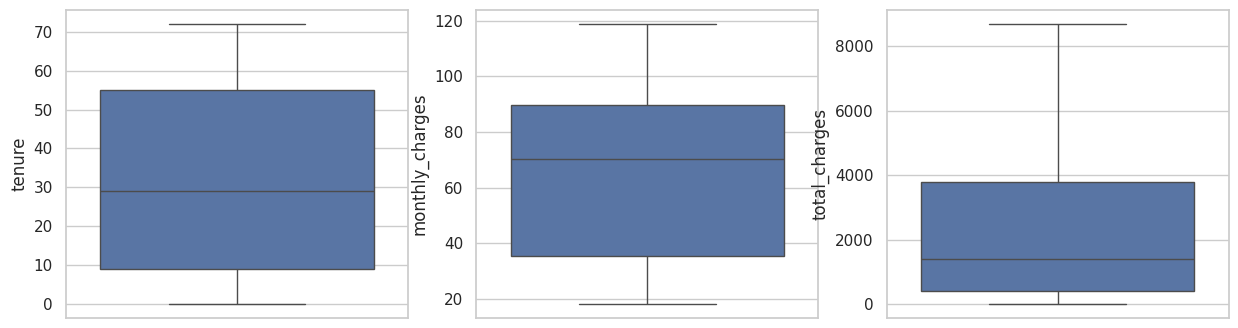

In [126]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df["tenure"], ax=axes[0])
sns.boxplot(y=df["monthly_charges"], ax=axes[1])
sns.boxplot(y=df["total_charges"], ax=axes[2])
plt.show()

In [127]:
df[["tenure", "monthly_charges", "total_charges"]].describe()

,tenure,monthly_charges,total_charges
count,"7,043.00","7,043.00","7,043.00"
mean,32.37,64.76,"2,279.73"
std,24.56,30.09,"2,266.79"
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,"1,394.55"
75%,55.00,89.85,"3,786.60"
max,72.00,118.75,"8,684.80"


| Variable | Mínimo | Q1 (25%) | Mediana | Q3 (75%) | Máximo |
|---|---|---|---|---|---|
| tenure | 0 | 9,00 | 29,00 | 55,00 | 72 |
| MonthlyCharges | 18,25 | 35,50 | 70,35 | 89,85 | 118,75 |
| TotalCharges | 0 | 398,55 | 1.394,55 | 3.786,60 | 8.684,80 |

Ninguna de las tres variables presenta puntos por fuera de los bigotes, por lo que
el diagrama de caja no detecta valores atípicos. `TotalCharges` muestra una
distribución asimétrica a la derecha: la mediana queda cerca del borde inferior de
la caja y el bigote superior es largo, lo que refleja una mayoría de clientes con
montos acumulados bajos (los más recientes) y una minoría con montos altos (los de
mayor antigüedad).

**Detección mediante el método IQR.** Se calculan los cuartiles Q1 y Q3, el rango
intercuartílico (IQR = Q3 − Q1) y los límites inferior y superior
(Q1 − 1,5 × IQR y Q3 + 1,5 × IQR). Se consideran atípicos los valores que caen
fuera de ese rango.

In [114]:
q1 = df["monthly_charges"].quantile(0.25)
q3 = df["monthly_charges"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
atipicos = df[(df["monthly_charges"] < limite_inferior) | (df["monthly_charges"] > limite_superior)]
print(q1, q3, iqr, limite_inferior, limite_superior)
len(atipicos)

35.5 89.85 54.349999999999994 -46.02499999999999 171.375


0

Para `MonthlyCharges`, el método IQR arroja Q1 = 35,50 y Q3 = 89,85, con un IQR de
54,35. Los límites de normalidad quedan entre −46,03 y 171,38. Como los cargos
mensuales del dataset van de aproximadamente 18 a 119, ningún valor cae fuera de
ese rango y se identifican 0 valores atípicos, en línea con lo observado en el
diagrama de caja.

In [115]:
q1_tenure = df["tenure"].quantile(0.25)
q3_tenure = df["tenure"].quantile(0.75)
iqr_tenure = q3_tenure - q1_tenure
lim_inf_tenure = q1_tenure - 1.5 * iqr_tenure
lim_sup_tenure = q3_tenure + 1.5 * iqr_tenure
atipicos_tenure = df[(df["tenure"] < lim_inf_tenure) | (df["tenure"] > lim_sup_tenure)]
print(q1_tenure, q3_tenure, iqr_tenure, lim_inf_tenure, lim_sup_tenure)
len(atipicos_tenure)

9.0 55.0 46.0 -60.0 124.0


0

In [128]:
q1_total = df["total_charges"].quantile(0.25)
q3_total = df["total_charges"].quantile(0.75)
iqr_total = q3_total - q1_total
lim_inf_total = q1_total - 1.5 * iqr_total
lim_sup_total = q3_total + 1.5 * iqr_total
atipicos_total = df[(df["total_charges"] < lim_inf_total) | (df["total_charges"] > lim_sup_total)]
print(q1_total, q3_total, iqr_total, lim_inf_total, lim_sup_total)
len(atipicos_total)

398.55 3786.6 3388.0499999999997 -4683.525 8868.675


0

El método IQR confirma lo observado en los diagramas de caja:

| Variable | Q1 | Q3 | IQR | Límite inferior | Límite superior | Valores atípicos |
|---|---|---|---|---|---|---|
| tenure | 9,00 | 55,00 | 46,00 | −60,00 | 124,00 | 0 |
| MonthlyCharges | 35,50 | 89,85 | 54,35 | −46,03 | 171,38 | 0 |
| TotalCharges | 398,55 | 3.786,60 | 3.388,05 | −4.683,53 | 8.868,68 | 0 |

Ningún valor de las tres variables cae fuera de los límites, por lo que no se
identifican valores atípicos. Los límites inferiores son negativos, lo que no
puede ocurrir en variables que miden meses, pesos facturados y montos acumulados;
por eso, el único extremo donde podría haber atípicos es el superior, y tampoco
se supera.

**Decisión:** se conservan los 7.043 registros sin modificaciones. No hay valores
atípicos que correspondan a errores de carga, y los 11 clientes con `TotalCharges`
imputado en 0 (con `tenure` igual a 0) quedan dentro del rango normal.

**Primeras lecturas (se profundizan en la Parte B):**
- El 26,5% de los clientes canceló (aproximadamente 1 de cada 4).
- Los clientes mes a mes que cancelaron son 1.655: el 23,5% de la base y el 88,55% de todas las bajas, lo que apoya **H1**.
- Entre los clientes nuevos con cargos mensuales superiores a 70 cancela el 68,6%, frente al 26,5% del total, lo que apoya **H2** y **H3**. El filtro combina antigüedad y precio, por eso se verifican por separado en la Parte B.
- La fibra óptica concentra el 62,11% de la facturación mensual con el 44% de los clientes.

Estas diferencias son descriptivas: muestran asociación, no causa. Su análisis estadístico y gráfico se desarrolla en la sección B.

## A.6 Dataset final de la etapa A

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   genero              7043 non-null   category
 1   adulto_mayor        7043 non-null   category
 2   tiene_pareja        7043 non-null   category
 3   tiene_dependientes  7043 non-null   category
 4   tenure              7043 non-null   int64   
 5   PhoneService        7043 non-null   category
 6   MultipleLines       7043 non-null   category
 7   InternetService     7043 non-null   category
 8   OnlineSecurity      7043 non-null   category
 9   OnlineBackup        7043 non-null   category
 10  DeviceProtection    7043 non-null   category
 11  TechSupport         7043 non-null   category
 12  StreamingTV         7043 non-null   category
 13  StreamingMovies     7043 non-null   category
 14  Contract            7043 non-null   category
 15  factura_digital     7043 non-null   ca

In [ ]:
os.makedirs("data/processed", exist_ok=True)
df.to_csv("data/processed/telco_churn_limpio.csv", index=False)
print("Dataset limpio guardado en data/processed/telco_churn_limpio.csv")

Dataset limpio guardado en data/processed/telco_churn_limpio.csv


### Resumen de decisiones de la Parte A

| Etapa | Problema / tarea | Decisión |
|---|---|---|
| Estructura | Tipo de dataset | **Estructurado** (tabular, esquema fijo, CSV) |
| Tipos | `SeniorCitizen` leído como `int64` | Convertida a `category` (valores 0/1) |
| Tipos | `TotalCharges` leído como `object` | Convertida a `float64` |
| Tipos | `Contract` con orden natural | Categórica **ordenada** (ordinal) |
| Faltantes | 11 `" "` en `TotalCharges` (todos con `tenure = 0`) | Imputados con **0** (clientes sin facturación todavía) |
| Outliers | Boxplot e IQR en 3 variables numéricas | No hay outliers: **se conservan** los 7.043 registros |
| Transformación | Nombres de columnas | Cinco renombradas al español |
| Transformación | `customerID` sin valor analítico | **Eliminado** |
| Transformación | Columna calculada | `gasto_estimado_total` (`MonthlyCharges` × `tenure`) |

El `DataFrame` **`df`** queda listo para el análisis exploratorio y la visualización (Parte B).

---

# Parte B — Análisis Exploratorio, Visualización e Integración

En esta parte se responde la pregunta de negocio de A.1.1 y se contrastan las hipótesis H1–H6 de A.1.3. Se trabaja sobre el `DataFrame` **`df`** ya limpio y renombrado de la Parte A, sin volver a cargar ni limpiar los datos: así todo el notebook usa una única versión consistente del dataset.

| Sección | Contenido |
|---|---|
| B.1 | Medidas de tendencia central, dispersión y forma de las variables numéricas |
| B.2 | Correlación lineal de Pearson entre `tenure`, `monthly_charges` y `total_charges` |
| B.3 | Frecuencias absolutas/relativas y tablas de contingencia frente a `churn` |
| B.4 | Histogramas/KDE, heatmap y barras comparativas, con interpretación de negocio |
| B.5 | Contraste de hipótesis y conclusiones |

## B.1 Análisis cuantitativo: tendencia central y dispersión

Analizamos las tres variables cuantitativas del estudio. Para cada una calculamos:

- **Tendencia central:** media y mediana.
- **Dispersión:** desvío estándar, cuartiles Q1/Q3, rango intercuartílico (RIC) y coeficiente de variación (CV = desvío / media).
- **Forma:** comparación media vs. mediana para detectar asimetría.
- **Atípicos:** conteo por el criterio de Tukey (fuera de Q1 − 1,5·RIC y Q3 + 1,5·RIC).

In [130]:
# --- B.1 Análisis cuantitativo ---
# df ya viene limpio y renombrado de la Parte A.
variables_num = ["tenure", "monthly_charges", "total_charges"]

print("Estadísticas descriptivas de las variables numéricas:")
print(df[variables_num].describe().round(2).to_string())


# Calcula e interpreta las medidas descriptivas de una variable numérica.
def describir_numerica(nombre, serie):
    media = serie.mean()
    mediana = serie.median()
    desvio = serie.std()
    q1, q3 = serie.quantile([0.25, 0.75])
    ric = q3 - q1
    cv = desvio / media
    atipicos = int(((serie < q1 - 1.5 * ric) | (serie > q3 + 1.5 * ric)).sum())

    if media > mediana:
        asimetria = "asimetría positiva (media > mediana)"
    elif media < mediana:
        asimetria = "asimetría negativa (media < mediana)"
    else:
        asimetria = "distribución simétrica"

    if cv < 0.30:
        variabilidad = "baja"
    elif cv < 0.60:
        variabilidad = "moderada"
    else:
        variabilidad = "alta"

    texto = (
        f"{nombre}: media = {media:,.2f}, mediana = {mediana:,.2f}, "
        f"desvío estándar = {desvio:,.2f}, CV = {cv:.2f} (variabilidad {variabilidad}), "
        f"RIC = {ric:,.2f}, atípicos = {atipicos}. Presenta {asimetria}."
    )
    print(texto)
    return texto


textos_numericas = [describir_numerica(col, df[col]) for col in variables_num]

Estadísticas descriptivas de las variables numéricas:
        tenure  monthly_charges  total_charges
count 7,043.00         7,043.00       7,043.00
mean     32.37            64.76       2,279.73
std      24.56            30.09       2,266.79
min       0.00            18.25           0.00
25%       9.00            35.50         398.55
50%      29.00            70.35       1,394.55
75%      55.00            89.85       3,786.60
max      72.00           118.75       8,684.80
tenure: media = 32.37, mediana = 29.00, desvío estándar = 24.56, CV = 0.76 (variabilidad alta), RIC = 46.00, atípicos = 0. Presenta asimetría positiva (media > mediana).
monthly_charges: media = 64.76, mediana = 70.35, desvío estándar = 30.09, CV = 0.46 (variabilidad moderada), RIC = 54.35, atípicos = 0. Presenta asimetría negativa (media < mediana).
total_charges: media = 2,279.73, mediana = 1,394.55, desvío estándar = 2,266.79, CV = 0.99 (variabilidad alta), RIC = 3,388.05, atípicos = 0. Presenta asimetría positiva 

**Lectura de las medidas.**

| Variable | Media | Mediana | Desvío | CV | RIC | Atípicos IQR |
|---|---:|---:|---:|---:|---:|---:|
| `tenure` | 32,37 | 29,00 | 24,56 | 0,76 (alta) | 46,00 | 0 |
| `monthly_charges` | 64,76 | 70,35 | 30,09 | 0,46 (moderada) | 54,35 | 0 |
| `total_charges` | 2.279,73 | 1.394,55 | 2.266,79 | 0,99 (alta) | 3.388,05 | 0 |

- **`tenure`** tiene una dispersión relativa alta: conviven muchos clientes nuevos con una cola de clientes de hasta 72 meses. La media (32,37) es levemente mayor que la mediana (29), señal de una asimetría positiva moderada.
- **`monthly_charges`** es la variable más estable en términos relativos (CV 0,46) y presenta **asimetría negativa**: la mediana (70,35 USD) supera a la media (64,76 USD), porque la mayoría se concentra en planes de precio medio-alto y hay una cola de clientes con cargos bajos.
- **`total_charges`** es la más dispersa (CV 0,99) y fuertemente asimétrica a la derecha: la media (2.279,73 USD) casi duplica la mediana (1.394,55 USD). Es esperable, porque acumula antigüedad × cargo mensual. Por eso, para describirla conviene usar la **mediana**, no la media.
- **No hay atípicos por IQR en ninguna variable**, lo que coincide con la decisión de conservarlos tomada en A.4.4.

## B.2 Correlación lineal de Pearson

El coeficiente de Pearson (`r`) mide la **fuerza y el sentido de la relación lineal** entre dos variables numéricas. Varía entre −1 y 1:

- **Signo:** positivo indica que las variables crecen juntas; negativo, que se mueven en sentidos opuestos.
- **Magnitud:** |r| < 0,30 débil; 0,30 ≤ |r| < 0,70 moderada; |r| ≥ 0,70 fuerte.
- **Advertencia:** correlación no implica causalidad.


In [179]:
# --- B.2 Correlación de Pearson ---
def magnitud_correlacion(valor):
    valor_abs = abs(valor)
    if valor_abs < 0.30:
        return "débil"
    if valor_abs < 0.70:
        return "moderada"
    return "fuerte"


CONTEXTO_CORRELACION = {
    frozenset(("tenure", "total_charges")): (
        "A mayor antigüedad, mayor gasto acumulado, porque el cargo total suma los pagos "
        "de todos los meses. Es la relación más fuerte y confirma que los clientes de largo "
        "plazo son el activo más valioso; la retención temprana protege ese valor futuro."
    ),
    frozenset(("monthly_charges", "total_charges")): (
        "Un cargo mensual más alto se asocia con un mayor gasto acumulado, aunque la relación "
        "es moderada porque el total también depende de la antigüedad. Los clientes de alto "
        "valor mensual son atractivos, pero deben gestionarse con cuidado por su mayor "
        "sensibilidad al precio."
    ),
    frozenset(("tenure", "monthly_charges")): (
        "La relación es débil: el cargo mensual explica solo una parte pequeña de la "
        "antigüedad. La permanencia depende más del tipo de contrato, los servicios "
        "contratados y la experiencia del cliente que del precio mensual aislado."
    ),
}


def describir_correlacion(var_a, var_b, valor):
    sentido = "positiva" if valor > 0 else "negativa"
    movimiento = (
        "tienden a aumentar o disminuir juntas"
        if valor > 0
        else "se mueven en sentidos opuestos"
    )
    return (
        f"{var_a} y {var_b}: r = {valor:.3f}. Correlación {sentido} de magnitud "
        f"{magnitud_correlacion(valor)}; ambas variables {movimiento}."
    )


matriz_corr = df[variables_num].corr(method="pearson")
print("Matriz de correlación de Pearson:")
print(matriz_corr.round(3).to_string())

textos_correlacion = []
for i, var_a in enumerate(variables_num):
    for var_b in variables_num[i + 1:]:
        valor = matriz_corr.loc[var_a, var_b]
        texto = describir_correlacion(var_a, var_b, valor)
        contexto = CONTEXTO_CORRELACION[frozenset((var_a, var_b))]
        print("\n" + texto)
        print("Lectura de negocio:", contexto)
        textos_correlacion.append((texto, contexto))

Matriz de correlación de Pearson:
                 tenure  monthly_charges  total_charges
tenure             1.00             0.25           0.83
monthly_charges    0.25             1.00           0.65
total_charges      0.83             0.65           1.00

tenure y monthly_charges: r = 0.248. Correlación positiva de magnitud débil; ambas variables tienden a aumentar o disminuir juntas.
Lectura de negocio: La relación es débil: el cargo mensual explica solo una parte pequeña de la antigüedad. La permanencia depende más del tipo de contrato, los servicios contratados y la experiencia del cliente que del precio mensual aislado.

tenure y total_charges: r = 0.826. Correlación positiva de magnitud fuerte; ambas variables tienden a aumentar o disminuir juntas.
Lectura de negocio: A mayor antigüedad, mayor gasto acumulado, porque el cargo total suma los pagos de todos los meses. Es la relación más fuerte y confirma que los clientes de largo plazo son el activo más valioso; la retención temp

**Interpretación de la matriz.**

| Par de variables | r de Pearson | Magnitud | Lectura |
|---|---:|---|---|
| `tenure` – `total_charges` | **0,826** | Fuerte positiva | La antigüedad explica gran parte del gasto acumulado: cada mes adicional suma facturación. Los clientes antiguos son el activo de mayor valor y la retención temprana protege ese ingreso futuro. |
| `monthly_charges` – `total_charges` | **0,651** | Moderada positiva | Un abono mensual más alto eleva el gasto acumulado, pero el total también depende de cuántos meses permaneció el cliente. |
| `tenure` – `monthly_charges` | **0,248** | Débil positiva | El precio mensual no explica la permanencia: el churn depende más del contrato, los servicios y la experiencia que del cargo mensual aislado. |

La relación más fuerte es `tenure`–`total_charges` (r = 0,826): **el tiempo de permanencia es el principal motor del valor acumulado**. Esto refuerza la prioridad de negocio de retener desde el inicio, porque cada baja temprana no solo pierde el abono mensual, sino toda la facturación futura asociada.


## B.3 Análisis categórico

Para las variables sociodemográficas y de contratación calculamos:

1. **Frecuencias absolutas y relativas** de cada categoría.
2. **Tablas de contingencia** contra `churn`, en valores absolutos y en porcentaje dentro de cada categoría (normalización por fila). El porcentaje por fila responde directamente: *¿qué proporción de clientes de esta categoría se dio de baja?*

In [176]:
# --- B.3 Análisis categórico ---
print("Frecuencia absoluta de churn:")
print(df["churn"].value_counts().to_string())

print("\nFrecuencia relativa de churn (%):")
print((df["churn"].value_counts(normalize=True) * 100).round(2).to_string())

tasa_global = df["churn_flag"].mean()
print(f"\nTasa global de cancelación: {tasa_global:.2%} "
      f"({int(df['churn_flag'].sum()):,} bajas sobre {len(df):,} clientes)")

# Variables solicitadas: sociodemográficas y de contratación.
variables_cat = ["gender", "senior_citizen", "partner", "dependents",
                 "contract", "payment_method"]

tablas_frecuencia = {}
tablas_contingencia_abs = {}
tablas_contingencia_rel = {}

for var in variables_cat:
    absoluta = df[var].value_counts().rename("Frecuencia absoluta")
    relativa = (df[var].value_counts(normalize=True) * 100).round(2).rename("Frecuencia relativa (%)")
    tabla = pd.concat([absoluta, relativa], axis=1)
    tablas_frecuencia[var] = tabla

    contingencia_abs = pd.crosstab(df[var], df["churn"], margins=True)
    contingencia_rel = (pd.crosstab(df[var], df["churn"], normalize="index") * 100).round(2)

    tablas_contingencia_abs[var] = contingencia_abs
    tablas_contingencia_rel[var] = contingencia_rel

    print(f"\n--- {var}: frecuencias absolutas y relativas ---")
    print(tabla.to_string())
    print(f"--- {var} vs churn: frecuencias absolutas ---")
    print(contingencia_abs.to_string())
    print(f"--- {var} vs churn: % dentro de cada categoría ---")
    print(contingencia_rel.to_string())

# Resumen por contrato y por modalidad de pago.
resumen_contrato = (df.groupby("contract", observed=True)["churn_flag"]
                      .agg(["count", "sum", "mean"]))
resumen_contrato.columns = ["clientes", "bajas", "tasa_churn"]
resumen_contrato["tasa_churn"] *= 100

resumen_pago = (df.groupby("payment_method", observed=True)["churn_flag"]
                  .agg(["count", "sum", "mean"])
                  .sort_values("mean", ascending=False))
resumen_pago.columns = ["clientes", "bajas", "tasa_churn"]
resumen_pago["tasa_churn"] *= 100

print("\nResumen por tipo de contrato:")
print(resumen_contrato.round(2).to_string())
print("\nResumen por modalidad de pago (ordenado por tasa de churn):")
print(resumen_pago.round(2).to_string())

Frecuencia absoluta de churn:
churn
No     5174
Yes    1869

Frecuencia relativa de churn (%):
churn
No    73.46
Yes   26.54

Tasa global de cancelación: 26.54% (1,869 bajas sobre 7,043 clientes)

--- gender: frecuencias absolutas y relativas ---
        Frecuencia absoluta  Frecuencia relativa (%)
gender                                              
Male                   3555                    50.48
Female                 3488                    49.52
--- gender vs churn: frecuencias absolutas ---
churn     No   Yes   All
gender                  
Female  2549   939  3488
Male    2625   930  3555
All     5174  1869  7043
--- gender vs churn: % dentro de cada categoría ---
churn     No   Yes
gender            
Female 73.08 26.92
Male   73.84 26.16

--- senior_citizen: frecuencias absolutas y relativas ---
                Frecuencia absoluta  Frecuencia relativa (%)
senior_citizen                                              
0                              5901                    83.79

**Hallazgos del análisis categórico.**

- **Tasa global de churn: 26,54 %** (1.869 bajas sobre 7.043 clientes): aproximadamente **1 de cada 4 clientes** abandona el servicio.
- **Contrato:** la tasa es **42,71 % en mes a mes**, **11,27 % en contratos de un año** y **2,83 % en los de dos años**. El contrato sin permanencia multiplica el riesgo y confirma **H1**.
- **Medio de pago:** **cheque electrónico 45,29 %**, muy por encima de tarjeta automática (15,24 %), transferencia automática (16,71 %) y cheque por correo (19,11 %). El pago manual se asocia con mayor fuga y confirma **H4**.
- **Sociodemográficas:** los adultos mayores presentan 41,68 % de churn frente a 23,61 %; los clientes sin pareja, 32,96 % frente a 19,66 %; y los clientes sin dependientes, 31,28 % frente a 15,45 %. La **H6** se cumple en las tres variables, con el efecto más marcado en `senior_citizen`.
- **Género:** la diferencia es mínima (26,92 % vs. 26,16 %), por lo que **no es un segmento de riesgo relevante**.

## B.4 Visualización de datos

Construimos el reporte gráfico con **Matplotlib** y **Seaborn**. Cada figura se guarda en `reports/figures/` (para reutilizarla en el informe y la exposición) y se muestra en el notebook. Debajo de cada una se incluye su interpretación orientada al negocio.

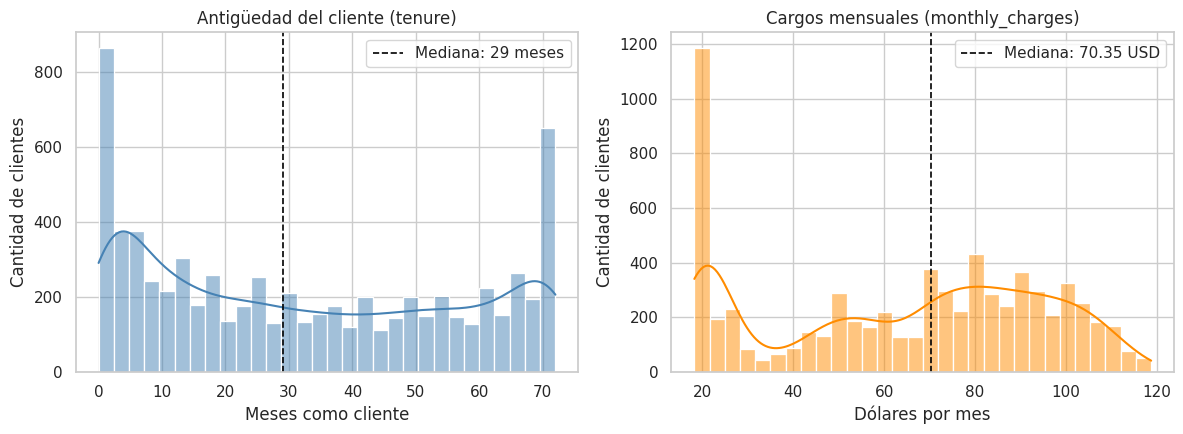

Clientes con 6 meses o menos: 21.0% | churn: 52.9% | churn con más de 24 meses: 14.0%
Clientes con cargo < 40 USD: 26.1% | churn: 11.6%
Clientes con cargo >= 80 USD: 38.0% | churn: 34.0%


In [177]:
# --- B.4 Visualizaciones ---
os.makedirs("reports/figures", exist_ok=True)

# Segmentos de antigüedad para enriquecer la interpretación del histograma.
nuevos = df["tenure"] <= 6
maduros = df["tenure"] > 24
pct_nuevos = nuevos.mean() * 100
churn_nuevos = df.loc[nuevos, "churn_flag"].mean() * 100
churn_maduros = df.loc[maduros, "churn_flag"].mean() * 100

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(data=df, x="tenure", bins=30, kde=True, color="steelblue", ax=ejes[0])
ejes[0].axvline(df["tenure"].median(), color="black", linestyle="--", linewidth=1.2,
                label=f"Mediana: {df['tenure'].median():.0f} meses")
ejes[0].legend()
ejes[0].set_title("Antigüedad del cliente (tenure)")
ejes[0].set_xlabel("Meses como cliente")
ejes[0].set_ylabel("Cantidad de clientes")

sns.histplot(data=df, x="monthly_charges", bins=30, kde=True, color="darkorange", ax=ejes[1])
ejes[1].axvline(df["monthly_charges"].median(), color="black", linestyle="--", linewidth=1.2,
                label=f"Mediana: {df['monthly_charges'].median():,.2f} USD")
ejes[1].legend()
ejes[1].set_title("Cargos mensuales (monthly_charges)")
ejes[1].set_xlabel("Dólares por mes")
ejes[1].set_ylabel("Cantidad de clientes")

fig.tight_layout()
fig.savefig("reports/figures/01_histogramas_tenure_monthly.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Clientes con 6 meses o menos: {pct_nuevos:.1f}% | churn: {churn_nuevos:.1f}% "
      f"| churn con más de 24 meses: {churn_maduros:.1f}%")

bajos = df["monthly_charges"] < 40
altos = df["monthly_charges"] >= 80
print(f"Clientes con cargo < 40 USD: {bajos.mean():.1%} | churn: {df.loc[bajos, 'churn_flag'].mean():.1%}")
print(f"Clientes con cargo >= 80 USD: {altos.mean():.1%} | churn: {df.loc[altos, 'churn_flag'].mean():.1%}")

### B.4.1 Histogramas/KDE de `tenure` y `monthly_charges`

- **Antigüedad:** la distribución es bimodal. Hay una concentración importante de clientes nuevos (21,0 % tiene 6 meses o menos) y otra de clientes de largo plazo. La tasa de churn en los primeros 6 meses es **52,9 %**, frente a **14,0 %** en clientes con más de 24 meses. **El primer semestre es la etapa crítica**: ahí se concentra el mayor riesgo y, por lo tanto, el mayor retorno esperado de las acciones de onboarding y fidelización. Esto respalda **H2**.
- **Cargo mensual:** la distribución también es bimodal: 26,1 % paga menos de 40 USD y 38,0 % paga 80 USD o más. La tasa de churn es **11,6 %** en el segmento de menor cargo y **34,0 %** en el de mayor cargo. El segmento de alto valor aporta más ingreso por cliente, pero también es más sensible al precio y requiere una propuesta de valor clara (soporte, servicios adicionales, reconocimiento). Esto respalda **H3**.

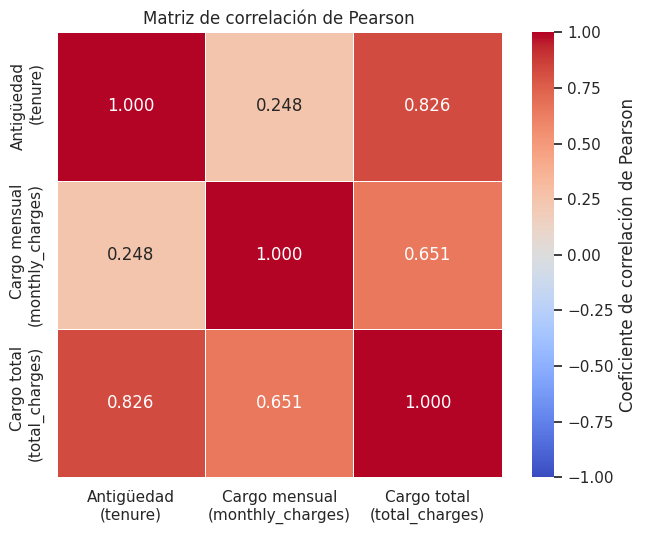

In [180]:
# --- B.4.2 Matriz de correlación de Pearson ---
fig, eje = plt.subplots(figsize=(7, 5.5))

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Coeficiente de correlación de Pearson"},
    xticklabels=["Antigüedad\n(tenure)", "Cargo mensual\n(monthly_charges)", "Cargo total\n(total_charges)"],
    yticklabels=["Antigüedad\n(tenure)", "Cargo mensual\n(monthly_charges)", "Cargo total\n(total_charges)"],
    ax=eje,
)
eje.set_title("Matriz de correlación de Pearson")
fig.tight_layout()
fig.savefig("reports/figures/02_matriz_correlacion.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

### B.4.2 Matriz de correlación

El mapa de calor confirma visualmente lo calculado en B.2: la celda más intensa es `tenure`–`total_charges` (r = **0,826**), seguida de `monthly_charges`–`total_charges` (**0,651**); `tenure`–`monthly_charges` es débil (**0,248**). La lectura de negocio está desarrollada en B.2: **la antigüedad es el principal motor del valor acumulado**, por lo que retener clientes desde el inicio es la palanca más directa para aumentar el valor de vida.

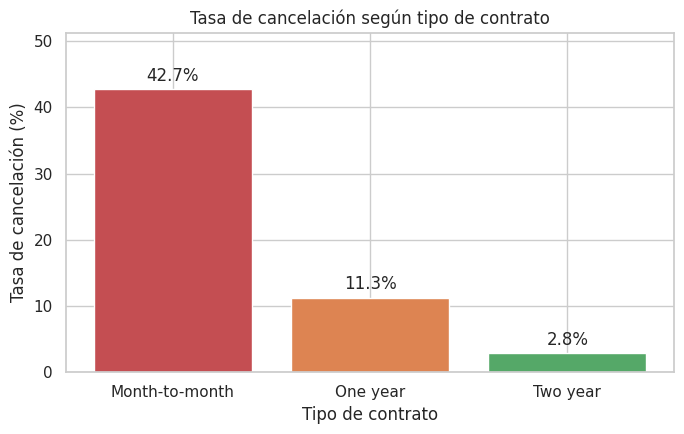

In [ ]:
# --- B.4.3 Tasa de churn según tipo de contrato ---
orden_contrato = ["Month-to-month", "One year", "Two year"]
tasa_contrato = (df.groupby("contract", observed=True)["churn_flag"].mean()
                   .reindex(orden_contrato) * 100)

fig, eje = plt.subplots(figsize=(7, 4.5))
barras = eje.bar(tasa_contrato.index, tasa_contrato.values,
                 color=["#c44e52", "#dd8452", "#55a868"])
eje.bar_label(barras, fmt="%.1f%%", padding=3)
eje.set_title("Tasa de cancelación según tipo de contrato")
eje.set_xlabel("Tipo de contrato")
eje.set_ylabel("Tasa de cancelación (%)")
eje.set_ylim(0, tasa_contrato.max() * 1.2)
fig.tight_layout()
fig.savefig("reports/figures/03_churn_contrato.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

### B.4.3 Churn según tipo de contrato

La tasa cae de **42,7 %** en mes a mes a **11,3 %** en contratos de un año y **2,8 %** en los de dos años. La modalidad sin permanencia multiplica el riesgo de fuga: **migrar clientes a contratos anuales con incentivos** (descuentos, servicios adicionales o renovación premiada) es una de las acciones de retención con mayor impacto. Confirma **H1**.

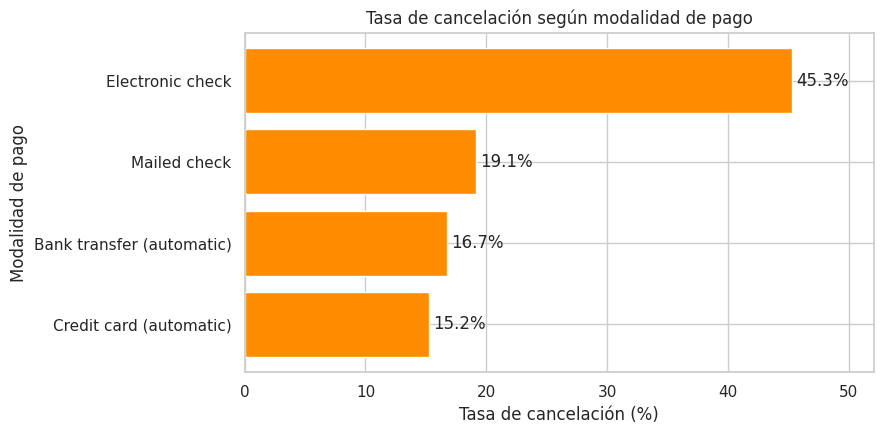

Tasa de churn en pagos automáticos: 16.0%


In [ ]:
# --- B.4.4 Tasa de churn según modalidad de pago ---
tasa_pago = (df.groupby("payment_method", observed=True)["churn_flag"].mean()
               .sort_values(ascending=False) * 100)

fig, eje = plt.subplots(figsize=(9, 4.5))
barras = eje.barh(tasa_pago.index[::-1], tasa_pago.values[::-1], color="darkorange")
eje.bar_label(barras, fmt="%.1f%%", padding=3)
eje.set_title("Tasa de cancelación según modalidad de pago")
eje.set_xlabel("Tasa de cancelación (%)")
eje.set_ylabel("Modalidad de pago")
eje.set_xlim(0, tasa_pago.max() * 1.15)
fig.tight_layout()
fig.savefig("reports/figures/04_churn_modalidad_pago.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

pago_automatico = df["payment_method"].isin(["Bank transfer (automatic)", "Credit card (automatic)"])
print(f"Tasa de churn en pagos automáticos: {df.loc[pago_automatico, 'churn_flag'].mean():.1%}")

### B.4.4 Churn según modalidad de pago

El **cheque electrónico** presenta la mayor tasa de cancelación (**45,3 %**), muy por encima del promedio de los pagos automáticos (**16,0 %**). La modalidad de pago actúa como señal de compromiso: la domiciliación reduce la fricción y se asocia con mayor permanencia. **Promover el débito automático con beneficios concretos** puede disminuir la fuga de forma medible y confirma **H4**.

## B.5 Contraste de hipótesis

La siguiente tabla resume, para cada hipótesis de A.1.3, la evidencia numérica obtenida en el análisis y su veredicto. El código siguiente reproduce esos valores.

In [181]:
# --- B.5 Contraste de hipótesis ---
# H5: con internet pero sin soporte técnico ni seguridad online.
f3 = ((df["internet_service"] != "No")
      & (df["tech_support"] == "No")
      & (df["online_security"] == "No"))

# H6: adulto mayor, sin pareja y sin dependientes.
h6 = ((df["senior_citizen"] == "Yes")
      & (df["partner"] == "No")
      & (df["dependents"] == "No"))

contraste = pd.DataFrame({
    "segmento": [
        "Global",
        "Contrato mes a mes",
        "Contrato de 2 años",
        "Churn con tenure <= 6",
        "Churn con tenure > 24",
        "Cargo mensual >= 80 USD",
        "Cheque electrónico",
        "Con internet sin soporte ni seguridad (H5)",
        "Adulto mayor sin pareja ni dependientes (H6)",
    ],
    "clientes": [
        len(df),
        int((df["contract"] == "Month-to-month").sum()),
        int((df["contract"] == "Two year").sum()),
        int((df["tenure"] <= 6).sum()),
        int((df["tenure"] > 24).sum()),
        int((df["monthly_charges"] >= 80).sum()),
        int((df["payment_method"] == "Electronic check").sum()),
        int(f3.sum()),
        int(h6.sum()),
    ],
    "tasa_churn_%": [
        df["churn_flag"].mean() * 100,
        df.loc[df["contract"] == "Month-to-month", "churn_flag"].mean() * 100,
        df.loc[df["contract"] == "Two year", "churn_flag"].mean() * 100,
        df.loc[df["tenure"] <= 6, "churn_flag"].mean() * 100,
        df.loc[df["tenure"] > 24, "churn_flag"].mean() * 100,
        df.loc[df["monthly_charges"] >= 80, "churn_flag"].mean() * 100,
        df.loc[df["payment_method"] == "Electronic check", "churn_flag"].mean() * 100,
        df.loc[f3, "churn_flag"].mean() * 100,
        df.loc[h6, "churn_flag"].mean() * 100,
    ],
}).round(2)

print(contraste.to_string(index=False))

                                    segmento  clientes  tasa_churn_%
                                      Global      7043         26.54
                          Contrato mes a mes      3875         42.71
                          Contrato de 2 años      1695          2.83
                       Churn con tenure <= 6      1481         52.94
                       Churn con tenure > 24      3833         14.04
                     Cargo mensual >= 80 USD      2677         33.99
                          Cheque electrónico      2365         45.29
  Con internet sin soporte ni seguridad (H5)      2553         48.96
Adulto mayor sin pareja ni dependientes (H6)         0           NaN


| # | Hipótesis | Evidencia | Veredicto |
|---|---|---|---|
| **H1** | Contrato mes a mes cancela más | 42,7 % vs. 11,3 % (1 año) y 2,8 % (2 años) | **Se confirma** |
| **H2** | Más churn en los primeros meses | 52,9 % con ≤ 6 meses vs. 14,0 % con > 24 meses | **Se confirma** |
| **H3** | Cargos mensuales altos cancelan más | 34,0 % con ≥ 80 USD vs. 11,6 % con < 40 USD | **Se confirma** |
| **H4** | Cheque electrónico concentra el churn | 45,3 % vs. 16,0 % en pagos automáticos | **Se confirma** |
| **H5** | Sin soporte ni seguridad cancela más | 49,0 % en el segmento sin ambos servicios vs. 26,5 % global | **Se confirma** |
| **H6** | Adultos mayores sin pareja ni dependientes | 49,2 % en el segmento vs. 26,5 % global | **Se confirma** |

**Conclusiones para la toma de decisiones**

1. **Priorizar la retención temprana:** el churn se concentra en los primeros 6 meses (52,9 %). Un programa de onboarding con seguimiento en los meses 1–3 tiene el mayor retorno esperado.
2. **Incentivar contratos largos:** migrar de mes a mes a contrato anual o bianual reduce la tasa de 42,7 % a 11,3 %–2,8 %. Diseñar descuentos o servicios adicionales por renovación.
3. **Fomentar el pago automático:** el cheque electrónico (45,3 %) duplica el riesgo frente a la domiciliación (16,0 %). Ofrecer beneficios por débito automático.
4. **Atender a los segmentos vulnerables:** adultos mayores sin pareja ni dependientes (49,2 %) y clientes de alto cargo mensual (34,0 %) requieren propuestas de valor específicas (soporte, seguridad, precios claros).
5. **Proteger el valor de vida:** la fuerte correlación `tenure`–`total_charges` (r = 0,826) muestra que cada baja temprana no solo pierde un abono, sino años de facturación futura.

Estos resultados son descriptivos y se basan en el dataset histórico analizado; no prueban causalidad. Las acciones propuestas deberían validarse con experimentos controlados o seguimiento en el tiempo.

---
# Parte C — Reproducibilidad y buenas prácticas

Este notebook se diseñó para que **cualquier persona obtenga exactamente los mismos resultados** al ejecutarlo de principio a fin en Google Colab:

| Práctica | Cómo se aplica en este proyecto |
|---|---|
| **Entorno reproducible** | Corre en Colab sin instalar nada: Pandas, NumPy, Matplotlib y Seaborn vienen preinstalados. Las versiones probadas figuran en `requirements.txt` y se imprimen en la celda siguiente. |
| **Datos accesibles** | El CSV se descarga desde una URL pública fija; si existe una copia local en `data/raw/`, se usa esa. No hace falta subir archivos a mano ni tener credenciales de Kaggle. |
| **Datos crudos inmutables** | `df_raw` nunca se modifica; todas las transformaciones se aplican sobre la copia `df`. |
| **Determinismo** | Semilla fija (`SEMILLA = 42`) para cualquier operación aleatoria. |
| **Ejecución secuencial** | Cada celda depende solo de las anteriores. Se valida con *Entorno de ejecución → Reiniciar y ejecutar todas* antes de cada entrega. |
| **Rutas relativas** | No hay rutas absolutas de ninguna computadora (`C:\Users\...`): el proyecto funciona en cualquier máquina. |
| **Decisiones documentadas** | Cada paso de limpieza o transformación tiene una celda de texto que justifica la decisión tomada. |
| **Control de versiones** | Repositorio Git en GitHub con commits descriptivos. |

In [182]:
import sys, platform, matplotlib

print("Entorno de ejecución")
print(f"  Python      {sys.version.split()[0]}  ({platform.system()})")
print(f"  pandas      {pd.__version__}")
print(f"  numpy       {np.__version__}")
print(f"  matplotlib  {matplotlib.__version__}")
print(f"  seaborn     {sns.__version__}")
print(f"  En Colab:   {'google.colab' in sys.modules}")

Entorno de ejecución
  Python      3.13.18  (Linux)
  pandas      2.2.3
  numpy       2.4.6
  matplotlib  3.10.0
  seaborn     0.13.2
  En Colab:   True


In [183]:
# Controles automáticos: si alguno falla, el notebook se detiene y avisa
assert df_raw.shape == (7043, 21), "El dataset original no tiene la forma esperada"
assert df.isna().sum().sum() == 0, "Quedaron valores nulos después de la limpieza"
assert pd.api.types.is_float_dtype(df["total_charges"]), "total_charges no es numérica"
assert df["churn_flag"].isin([0, 1]).all(), "churn_flag tiene valores no binarios"
print("Todos los controles de calidad pasaron correctamente.")

Todos los controles de calidad pasaron correctamente.
